<a href="https://colab.research.google.com/github/MNMARQUES/Python/blob/main/Projeto02/Python_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

%pip install -q pandas numpy matplotlib seaborn

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração para resultados reproduzíveis
rng = np.random.default_rng(42)

# Diretório de trabalho no Colab
BASE_DIR = Path("/content/desafio_modulo_2")
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
GRAFICOS_DIR = OUTPUT_DIR / "graficos"

DATA_DIR.mkdir(parents=True, exist_ok=True)
GRAFICOS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

print("Ambiente preparado com sucesso!")
print("Pasta do projeto:", BASE_DIR)


Ambiente preparado com sucesso!
Pasta do projeto: /content/desafio_modulo_2


In [5]:

quantidade = 100
ids = np.arange(1001, 1001 + quantidade)

# Dataset de características físicas
df_fisico = pd.DataFrame({
    "id_cliente": ids,
    "idade": rng.integers(18, 76, quantidade),
    "altura_m": np.round(
        rng.normal(1.68, 0.10, quantidade), 2
    ),
    "peso_kg": np.round(
        rng.normal(72, 15, quantidade), 1
    ),
})

# Dataset de informações demográficas
df_demografico = pd.DataFrame({
    "id_cliente": ids,
    "sexo": rng.choice(
        ["Feminino", "Masculino"], quantidade
    ),
    "cidade": rng.choice(
        [
            "Rio de Janeiro",
            "Niterói",
            "Duque de Caxias",
            "Nova Iguaçu",
            "Petrópolis",
        ],
        quantidade,
    ),
    "escolaridade": rng.choice(
        [
            "Fundamental",
            "Médio",
            "Superior",
            "Pós-graduação",
        ],
        quantidade,
    ),
    "renda_mensal": np.round(
        rng.normal(4200, 1800, quantidade).clip(1200, 15000),
        2,
    ),
})

# Inserir valores ausentes intencionalmente
df_fisico.loc[[3, 15, 28], "altura_m"] = np.nan
df_fisico.loc[[7, 32], "peso_kg"] = np.nan
df_fisico.loc[[19], "idade"] = np.nan

df_demografico.loc[[5, 17, 40], "cidade"] = np.nan
df_demografico.loc[[9, 26], "escolaridade"] = np.nan
df_demografico.loc[[12, 35], "renda_mensal"] = np.nan

# Inserir uma linha integralmente duplicada em cada dataset
df_fisico = pd.concat(
    [df_fisico, df_fisico.iloc[[0]]],
    ignore_index=True,
)

df_demografico = pd.concat(
    [df_demografico, df_demografico.iloc[[1]]],
    ignore_index=True,
)

# Salvar os arquivos CSV
df_fisico.to_csv(
    DATA_DIR / "clientes_caracteristicas_fisicas.csv",
    index=False,
)
df_demografico.to_csv(
    DATA_DIR / "clientes_informacoes_demograficas.csv",
    index=False,
)

print("Datasets criados com sucesso!")
print("Características físicas:", df_fisico.shape)
print("Informações demográficas:", df_demografico.shape)

display(df_fisico.head())
display(df_demografico.head())


Datasets criados com sucesso!
Características físicas: (101, 4)
Informações demográficas: (101, 5)


,id_cliente,idade,altura_m,peso_kg
0,1001,23.0,1.75,88.0
1,1002,62.0,1.69,74.4
2,1003,55.0,1.71,69.6
3,1004,43.0,NaN,56.5
4,1005,43.0,1.53,46.9


,id_cliente,sexo,cidade,escolaridade,renda_mensal
0,1001,Masculino,Nova Iguaçu,Pós-graduação,5026.89
1,1002,Feminino,Nova Iguaçu,Pós-graduação,5463.52
2,1003,Masculino,Niterói,Superior,4448.83
3,1004,Feminino,Niterói,Médio,5568.24
4,1005,Feminino,Rio de Janeiro,Fundamental,4612.58


In [6]:

df_fisico = pd.read_csv(
    DATA_DIR / "clientes_caracteristicas_fisicas.csv"
)
df_demografico = pd.read_csv(
    DATA_DIR / "clientes_informacoes_demograficas.csv"
)

def inspecionar_dados(nome, df):
    print(f"\n{'=' * 55}")
    print(nome)
    print("=" * 55)

    print("\nDimensões:", df.shape)

    print("\nPrimeiras linhas:")
    display(df.head())

    print("\nInformações das colunas:")
    df.info()

    print("\nEstatísticas descritivas:")
    display(df.describe(include="all").T)

    print("\nValores ausentes por coluna:")
    display(df.isna().sum().to_frame("valores_ausentes"))

    print("\nLinhas duplicadas:", df.duplicated().sum())

inspecionar_dados(
    "Características físicas",
    df_fisico,
)

inspecionar_dados(
    "Informações demográficas",
    df_demografico,
)



Características físicas

Dimensões: (101, 4)

Primeiras linhas:


,id_cliente,idade,altura_m,peso_kg
0,1001,23.0,1.75,88.0
1,1002,62.0,1.69,74.4
2,1003,55.0,1.71,69.6
3,1004,43.0,NaN,56.5
4,1005,43.0,1.53,46.9



Informações das colunas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id_cliente  101 non-null    int64  
 1   idade       100 non-null    float64
 2   altura_m    98 non-null     float64
 3   peso_kg     99 non-null     float64
dtypes: float64(3), int64(1)
memory usage: 3.3 KB

Estatísticas descritivas:


,count,mean,std,min,25%,50%,75%,max
id_cliente,101.0,1050.009901,29.283270,1001.00,1025.0000,1050.00,1075.0000,1100.00
idade,100.0,47.840000,16.019382,20.00,35.5000,47.50,62.0000,74.00
altura_m,98.0,1.667245,0.089267,1.47,1.6025,1.66,1.7275,1.97
peso_kg,99.0,70.927273,15.053793,39.80,59.3000,69.70,78.5500,109.80



Valores ausentes por coluna:


...


Informações das colunas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_cliente    101 non-null    int64  
 1   sexo          101 non-null    object 
 2   cidade        98 non-null     object 
 3   escolaridade  99 non-null     object 
 4   renda_mensal  99 non-null     float64
dtypes: float64(1), int64(1), object(3)
memory usage: 4.1+ KB

Estatísticas descritivas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_cliente,101.0,NaN,NaN,NaN,1050.019802,29.266698,1001.0,1025.0,1050.0,1075.0,1100.0
sexo,101,2,Masculino,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cidade,98,5,Nova Iguaçu,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
escolaridade,99,4,Pós-graduação,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
renda_mensal,99.0,NaN,NaN,NaN,4311.123333,1641.290629,1200.0,3184.53,4365.83,5356.28,8875.81



Valores ausentes por coluna:


,valores_ausentes
id_cliente,0
sexo,0
cidade,3
escolaridade,2
renda_mensal,2



Linhas duplicadas: 1


In [7]:

def limpar_dados(nome, df):
    linhas_originais = len(df)
    total_ausentes = int(df.isna().sum().sum())
    linhas_com_ausentes = int(df.isna().any(axis=1).sum())
    duplicados_originais = int(df.duplicated().sum())

    # Eliminar linhas com pelo menos um valor ausente
    df_limpo = df.dropna().copy()

    linhas_apos_dropna = len(df_limpo)

    # Eliminar linhas integralmente duplicadas
    df_limpo = df_limpo.drop_duplicates().copy()

    resumo = {
        "dataset": nome,
        "linhas_originais": linhas_originais,
        "celulas_ausentes": total_ausentes,
        "linhas_com_ausentes": linhas_com_ausentes,
        "duplicados_originais": duplicados_originais,
        "linhas_apos_dropna": linhas_apos_dropna,
        "linhas_finais": len(df_limpo),
        "linhas_removidas": linhas_originais - len(df_limpo),
    }

    return df_limpo, resumo


df_fisico_limpo, resumo_fisico = limpar_dados(
    "Características físicas", df_fisico
)

df_demografico_limpo, resumo_demografico = limpar_dados(
    "Informações demográficas", df_demografico
)

resumo_tratamento = pd.DataFrame([
    resumo_fisico,
    resumo_demografico,
])

display(resumo_tratamento)

resumo_tratamento.to_csv(
    OUTPUT_DIR / "resumo_tratamento.csv",
    index=False,
)

df_fisico_limpo.to_csv(
    OUTPUT_DIR / "clientes_caracteristicas_fisicas_limpo.csv",
    index=False,
)

df_demografico_limpo.to_csv(
    OUTPUT_DIR / "clientes_informacoes_demograficas_limpo.csv",
    index=False,
)

print("Tratamento concluído!")


,dataset,linhas_originais,celulas_ausentes,linhas_com_ausentes,duplicados_originais,linhas_apos_dropna,linhas_finais,linhas_removidas
0,Características físicas,101,6,6,1,95,94,7
1,Informações demográficas,101,7,7,1,94,93,8


Tratamento concluído!


In [9]:

df_clientes = pd.merge(
    df_fisico_limpo,
    df_demografico_limpo,
    on="id_cliente",
    how="inner",
    validate="one_to_one",
)

print("Quantidade de clientes integrados:", len(df_clientes))
display(df_clientes.head(10))

print("\nEstatísticas das variáveis numéricas:")
display(
    df_clientes[
        ["idade", "altura_m", "peso_kg", "renda_mensal"]
    ].describe().round(2)
)

print("\nClientes por sexo:")
display(df_clientes["sexo"].value_counts().to_frame("quantidade"))

print("\nClientes por cidade:")
display(df_clientes["cidade"].value_counts().to_frame("quantidade"))

print("\nClientes por escolaridade:")
display(
    df_clientes["escolaridade"]
    .value_counts()
    .to_frame("quantidade")
)

print("\nRenda média por escolaridade:")
renda_escolaridade = (
    df_clientes.groupby("escolaridade")["renda_mensal"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)
display(renda_escolaridade.to_frame("renda_media"))

print("\nIdade média por cidade:")
display(
    df_clientes.groupby("cidade")["idade"]
    .mean()
    .round(2)
    .to_frame("idade_media")
)

print("\nMatriz de correlação:")
correlacao = df_clientes[
    ["idade", "altura_m", "peso_kg", "renda_mensal"]
].corr()
display(correlacao.round(2))

df_clientes.to_csv(
    OUTPUT_DIR / "clientes_integrados_limpos.csv",
    index=False,
)


Quantidade de clientes integrados: 87


,id_cliente,idade,altura_m,peso_kg,sexo,cidade,escolaridade,renda_mensal
0,1001,23.0,1.75,88.0,Masculino,Nova Iguaçu,Pós-graduação,5026.89
1,1002,62.0,1.69,74.4,Feminino,Nova Iguaçu,Pós-graduação,5463.52
2,1003,55.0,1.71,69.6,Masculino,Niterói,Superior,4448.83
3,1005,43.0,1.53,46.9,Feminino,Rio de Janeiro,Fundamental,4612.58
4,1007,22.0,1.63,71.2,Feminino,Duque de Caxias,Fundamental,2931.59
5,1009,29.0,1.65,74.0,Feminino,Rio de Janeiro,Pós-graduação,4554.20
6,1011,48.0,1.59,64.5,Feminino,Nova Iguaçu,Pós-graduação,3491.27
7,1012,74.0,1.78,54.2,Feminino,Niterói,Fundamental,5138.10
8,1014,62.0,1.65,61.1,Feminino,Niterói,Fundamental,3988.42
9,1015,59.0,1.70,103.9,Masculino,Duque de Caxias,Médio,5693.13



Estatísticas das variáveis numéricas:


,idade,altura_m,peso_kg,renda_mensal
count,87.00,87.00,87.00,87.00
mean,48.98,1.66,71.08,4382.37
std,15.57,0.09,14.97,1600.97
min,20.00,1.47,39.80,1200.00
25%,37.50,1.59,61.10,3420.82
50%,49.00,1.66,69.70,4448.83
75%,62.00,1.72,77.75,5279.96
max,74.00,1.97,109.80,8875.81



Clientes por sexo:


...

,renda_media
escolaridade,
Médio,4665.88
Superior,4392.15
Pós-graduação,4231.27
Fundamental,4227.85



Idade média por cidade:


,idade_media
cidade,
Duque de Caxias,49.00
Niterói,53.50
Nova Iguaçu,46.88
Petrópolis,46.93
Rio de Janeiro,50.83



Matriz de correlação:


,idade,altura_m,peso_kg,renda_mensal
idade,1.00,0.06,-0.11,0.22
altura_m,0.06,1.00,0.20,-0.11
peso_kg,-0.11,0.20,1.00,-0.24
renda_mensal,0.22,-0.11,-0.24,1.00


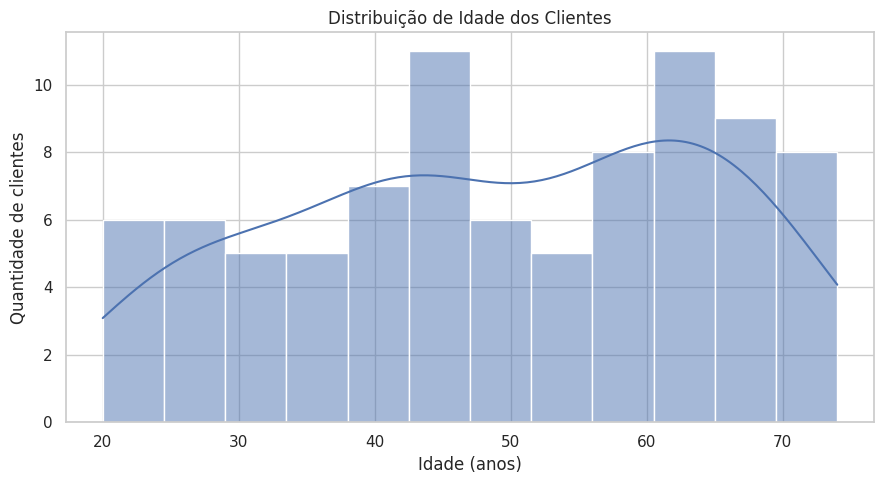

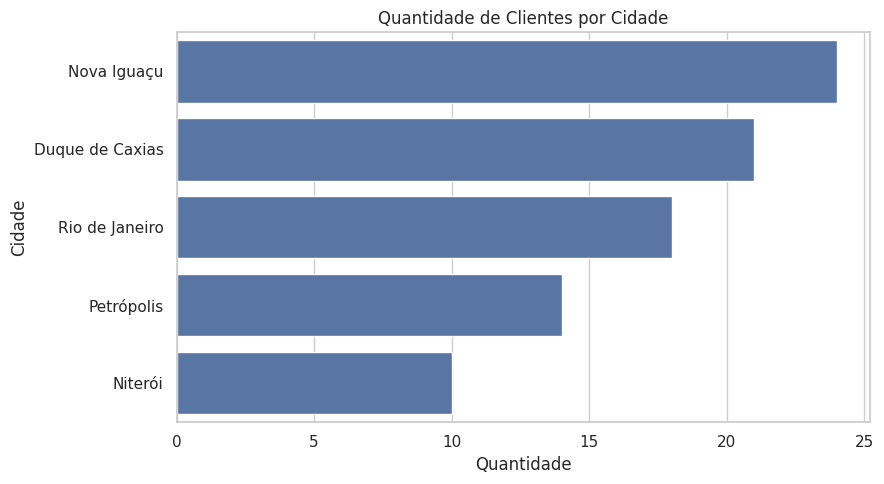

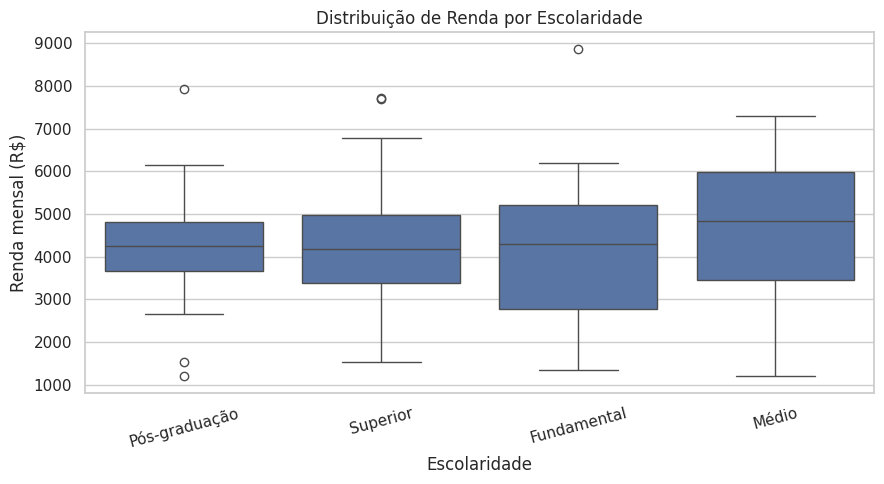

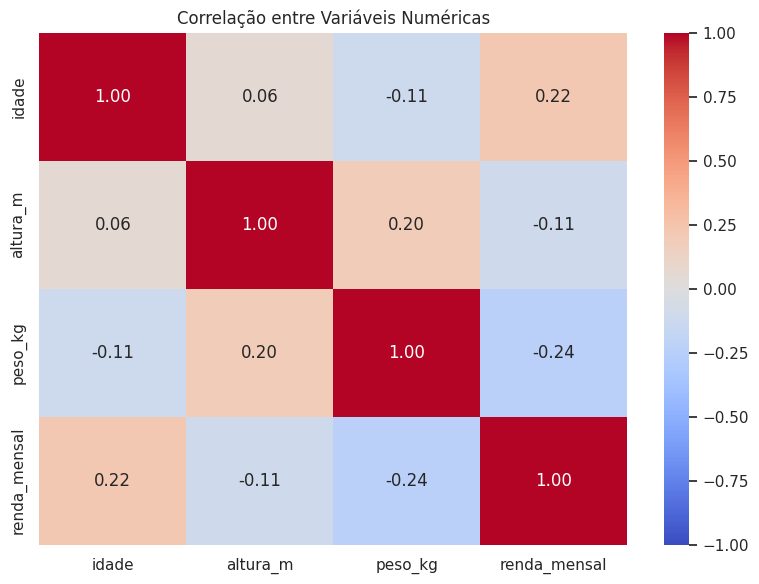

In [10]:

# Gráfico 1: distribuição das idades
plt.figure(figsize=(9, 5))
sns.histplot(data=df_clientes, x="idade", bins=12, kde=True)
plt.title("Distribuição de Idade dos Clientes")
plt.xlabel("Idade (anos)")
plt.ylabel("Quantidade de clientes")
plt.tight_layout()
plt.savefig(GRAFICOS_DIR / "distribuicao_idade.png", dpi=150)
plt.show()

# Gráfico 2: clientes por cidade
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df_clientes,
    y="cidade",
    order=df_clientes["cidade"].value_counts().index,
)
plt.title("Quantidade de Clientes por Cidade")
plt.xlabel("Quantidade")
plt.ylabel("Cidade")
plt.tight_layout()
plt.savefig(GRAFICOS_DIR / "clientes_por_cidade.png", dpi=150)
plt.show()

# Gráfico 3: renda por escolaridade
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df_clientes,
    x="escolaridade",
    y="renda_mensal",
)
plt.title("Distribuição de Renda por Escolaridade")
plt.xlabel("Escolaridade")
plt.ylabel("Renda mensal (R$)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(
    GRAFICOS_DIR / "renda_por_escolaridade.png",
    dpi=150,
)
plt.show()

# Gráfico 4: correlação
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
)
plt.title("Correlação entre Variáveis Numéricas")
plt.tight_layout()
plt.savefig(GRAFICOS_DIR / "matriz_correlacao.png", dpi=150)
plt.show()


In [11]:

relatorio = f"""
RELATÓRIO — DESAFIO MÓDULO 2
Bibliotecas para Análise de Dados

IMPORTANTE:
Foram utilizados dados fictícios para fins didáticos.

1. TRATAMENTO
Clientes integrados: {len(df_clientes)}
Linhas físicas originais: {len(df_fisico)}
Linhas físicas após limpeza: {len(df_fisico_limpo)}
Linhas demográficas originais: {len(df_demografico)}
Linhas demográficas após limpeza: {len(df_demografico_limpo)}

2. ESTATÍSTICAS
Idade média: {df_clientes['idade'].mean():.2f} anos
Idade mediana: {df_clientes['idade'].median():.2f} anos
Altura média: {df_clientes['altura_m'].mean():.2f} m
Peso médio: {df_clientes['peso_kg'].mean():.2f} kg
Renda média: R$ {df_clientes['renda_mensal'].mean():.2f}
Renda mediana: R$ {df_clientes['renda_mensal'].median():.2f}

3. DISTRIBUIÇÕES
Cidade mais frequente: {df_clientes['cidade'].mode().iloc[0]}
Escolaridade com maior renda média:
{renda_escolaridade.index[0]}

4. CONCLUSÃO
O projeto aplicou técnicas de coleta, inspeção, limpeza,
integração, análise estatística e visualização de dados.

Os resultados descrevem exclusivamente os dados sintéticos
criados para este exercício e não representam clientes reais.
"""

print(relatorio)

(OUTPUT_DIR / "relatorio_final.txt").write_text(
    relatorio,
    encoding="utf-8",
)

print("Relatório salvo com sucesso!")



RELATÓRIO — DESAFIO MÓDULO 2
Bibliotecas para Análise de Dados

IMPORTANTE:
Foram utilizados dados fictícios para fins didáticos.

1. TRATAMENTO
Clientes integrados: 87
Linhas físicas originais: 101
Linhas físicas após limpeza: 94
Linhas demográficas originais: 101
Linhas demográficas após limpeza: 93

2. ESTATÍSTICAS
Idade média: 48.98 anos
Idade mediana: 49.00 anos
Altura média: 1.66 m
Peso médio: 71.08 kg
Renda média: R$ 4382.37
Renda mediana: R$ 4448.83

3. DISTRIBUIÇÕES
Cidade mais frequente: Nova Iguaçu
Escolaridade com maior renda média:
Médio

4. CONCLUSÃO
O projeto aplicou técnicas de coleta, inspeção, limpeza,
integração, análise estatística e visualização de dados.

Os resultados descrevem exclusivamente os dados sintéticos
criados para este exercício e não representam clientes reais.

Relatório salvo com sucesso!


In [12]:

import shutil
from google.colab import files

arquivo_zip = shutil.make_archive(
    "/content/desafio_modulo_2_resultados",
    "zip",
    root_dir=BASE_DIR,
)

files.download(arquivo_zip)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>